## Lab 6
#### Name: Madhura Likhar
#### Section: C
#### Roll no.: 22
#### Date of Performance: 22-09-26

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    f1_score,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df=pd.read_csv("seeds_new.csv")

In [3]:
df=df.dropna(axis=1, how="all")

In [4]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

In [5]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [6]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [7]:
df.shape

(210, 8)

In [8]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='object')

In [9]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1, 2, 3)",int64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [11]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [12]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.drop_duplicates()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1
...,...,...,...,...,...,...,...,...
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3


### Vizualization

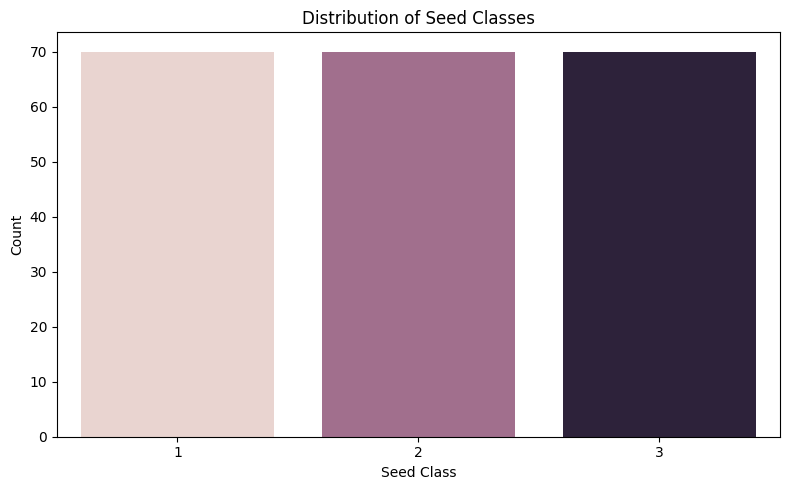

In [15]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Class (1, 2, 3)", hue="Class (1, 2, 3)", legend=False)
plt.title("Distribution of Seed Classes")
plt.xlabel("Seed Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


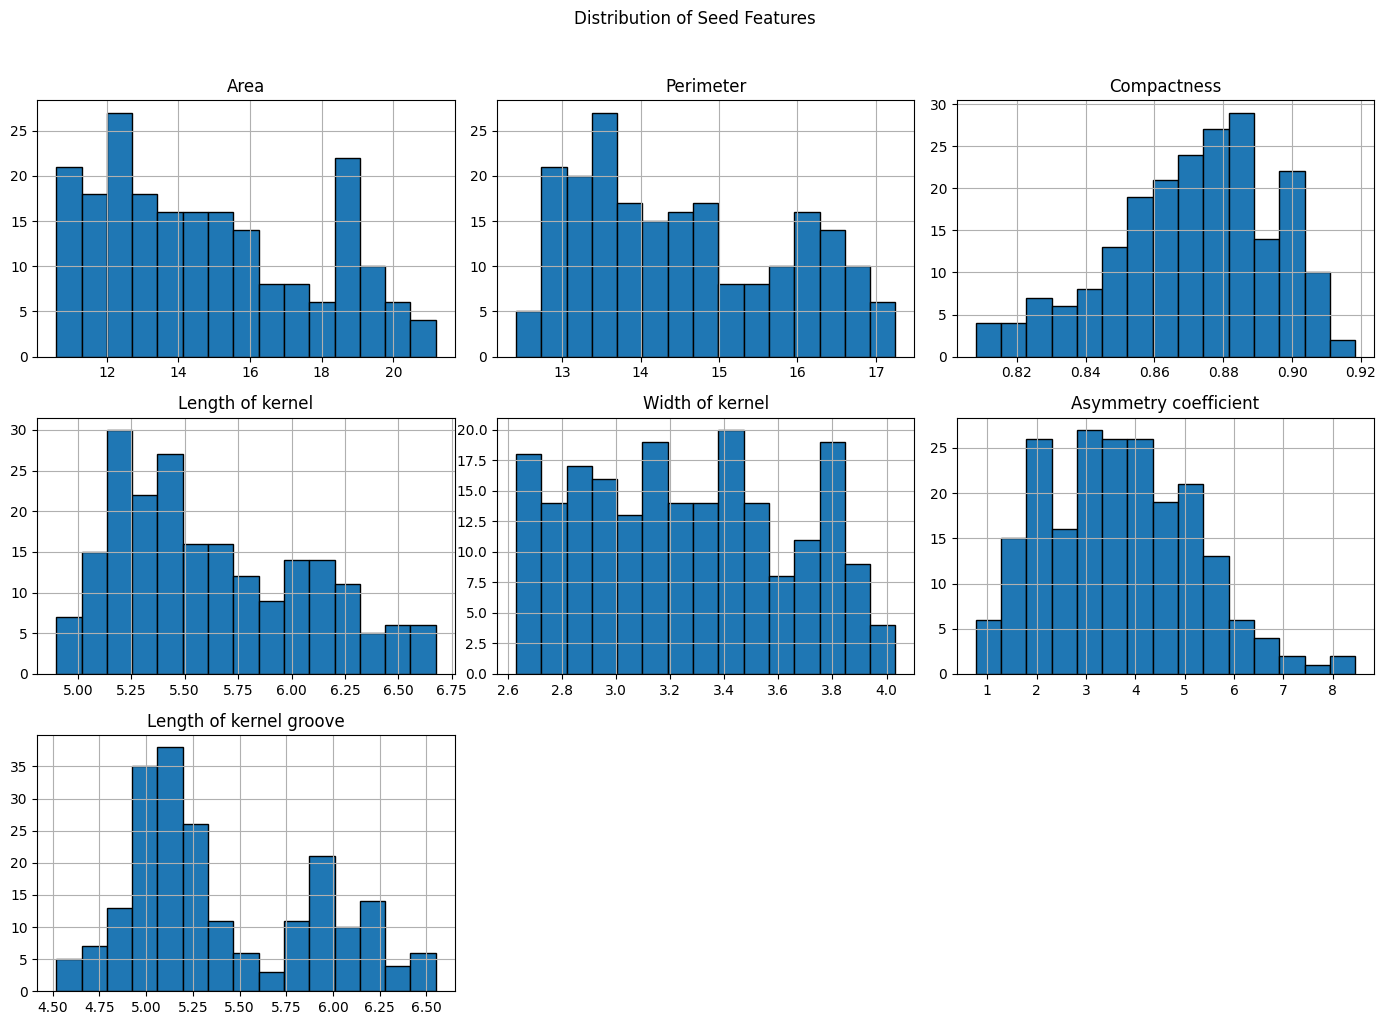

In [16]:

features = df.drop("Class (1, 2, 3)", axis=1)

features.hist(figsize=(14, 10), bins=15, edgecolor="black")
plt.suptitle("Distribution of Seed Features", y=1.02)
plt.tight_layout()
plt.show()


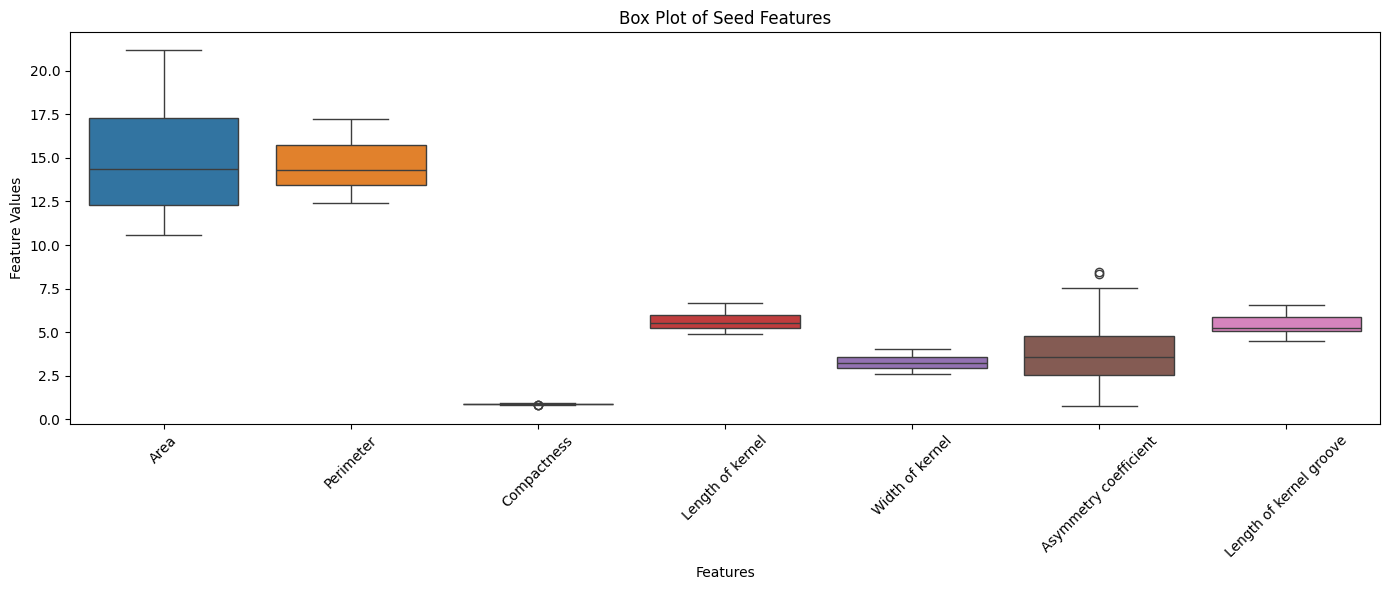

In [17]:

plt.figure(figsize=(14, 6))
sns.boxplot(data=features)
plt.title("Box Plot of Seed Features")
plt.xlabel("Features")
plt.ylabel("Feature Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


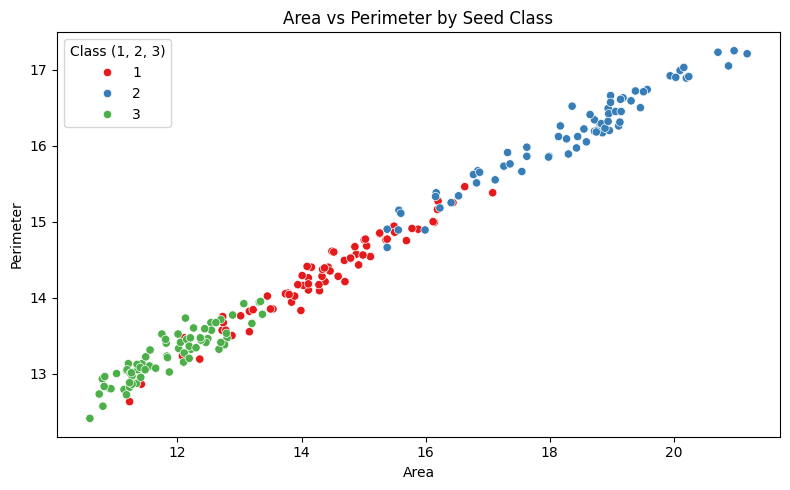

In [18]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Area",
    y="Perimeter",
    hue="Class (1, 2, 3)",
    palette="Set1"
)
plt.title("Area vs Perimeter by Seed Class")
plt.xlabel("Area")
plt.ylabel("Perimeter")
plt.tight_layout()
plt.show()


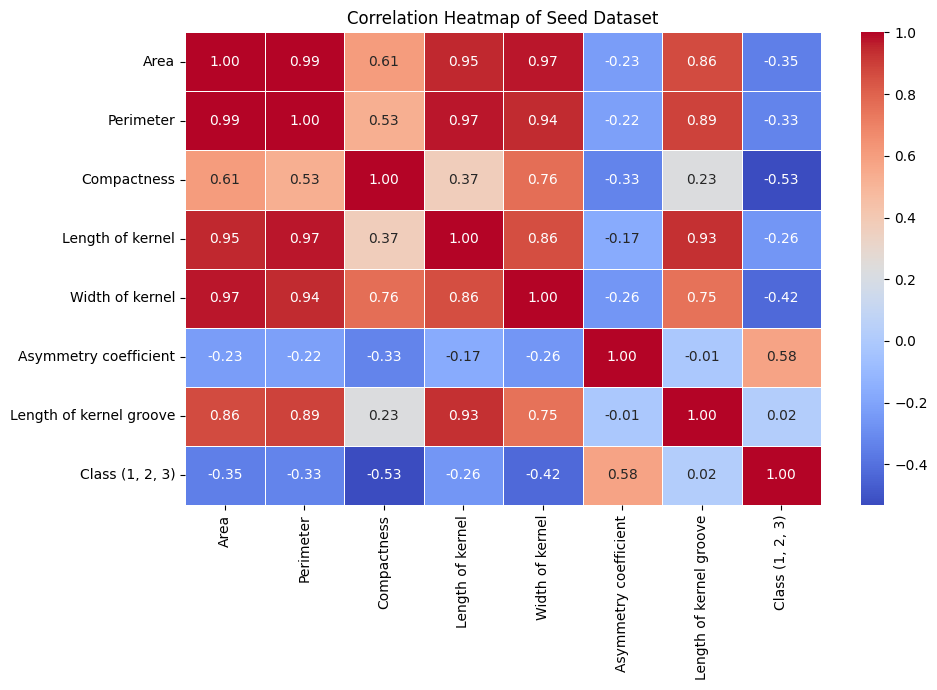

In [19]:

plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Seed Dataset")
plt.tight_layout()
plt.show()


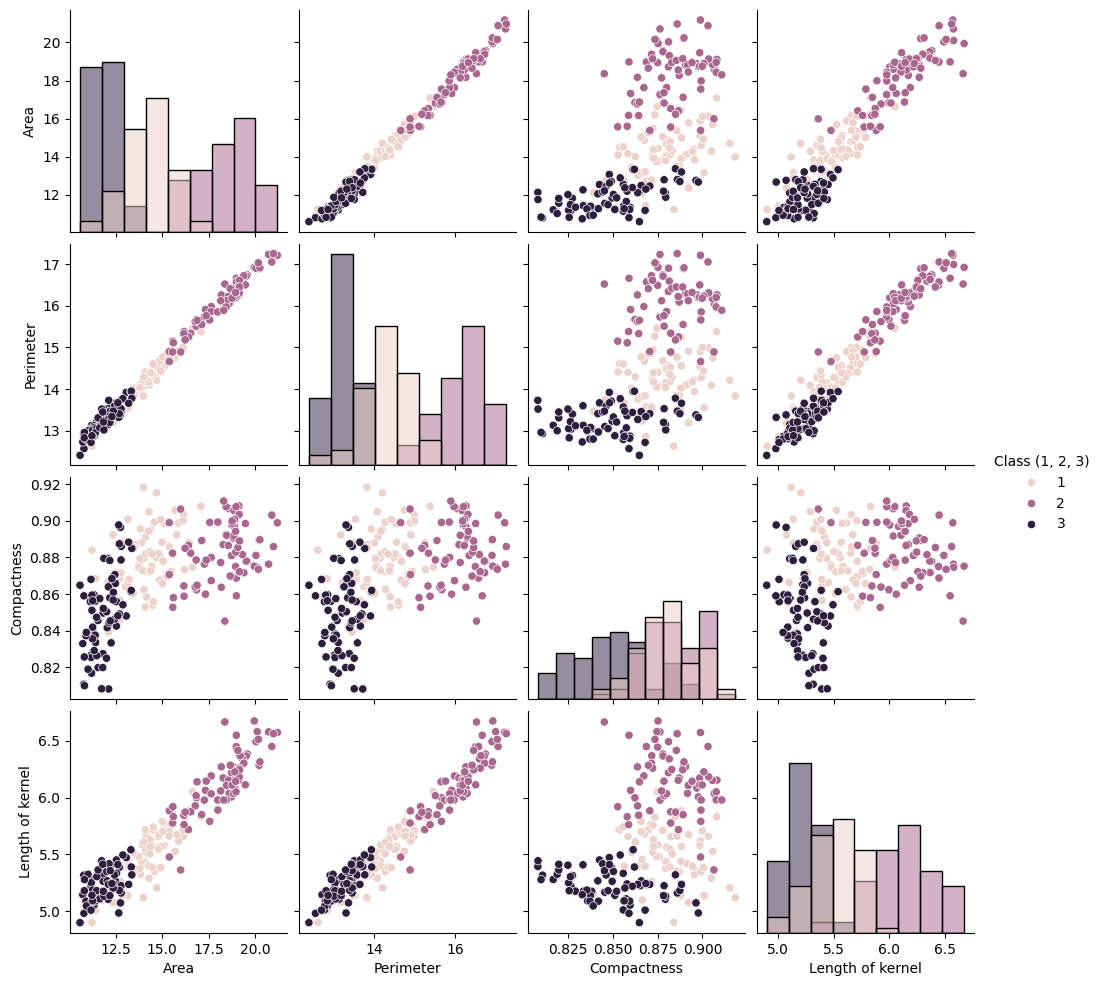

In [20]:

selected_features = list(features.columns[:4]) + ["Class (1, 2, 3)"]

sns.pairplot(
    df[selected_features],
    hue="Class (1, 2, 3)",
    diag_kind="hist"
)
plt.show()


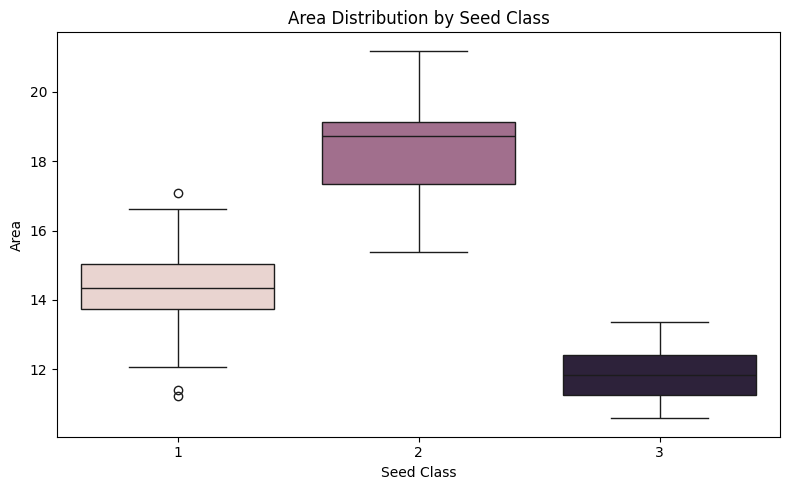

In [21]:

selected_feature = features.columns[0]

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Class (1, 2, 3)",
    y=selected_feature,
    hue="Class (1, 2, 3)",
    legend=False
)
plt.title(f"{selected_feature} Distribution by Seed Class")
plt.xlabel("Seed Class")
plt.ylabel(selected_feature)
plt.tight_layout()
plt.show()


#### Algorithm

In [22]:
X=df.drop("Class (1, 2, 3)", axis=1)
y_original=df["Class (1, 2, 3)"]

print("Input shape:", X.shape)
print("Output shape:", y_original.shape)

Input shape: (210, 7)
Output shape: (210,)


In [23]:
y=y_original-1

print("Original classes:")
print(sorted(y_original.unique()))
print("\nANN encoded classes:")
print(y.unique())

Original classes:
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes:
[0 1 2]


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("X_train samples:", X_train.shape[0])
print("X_test samples:", X_test.shape[0])

X_train samples: 168
X_test samples: 42


In [25]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [27]:
print("First 5 rows of scaled training samples")
print(X_train[:5])

First 5 rows of scaled training samples
[[-1.17682401 -1.1750583  -1.02169157 -1.02785725 -1.35751947  1.43188942
  -0.82441016]
 [-0.87298429 -1.06714618  0.86676795 -1.26492983 -0.59897345 -0.3056117
  -1.63150367]
 [-0.12719589  0.01968295 -0.66917913  0.25096694 -0.40933695 -1.4432301
   0.1615857 ]
 [-1.29421662 -1.37546651 -0.66498255 -1.41310019 -1.26136575  1.7668294
  -0.72886004]
 [-0.58295547 -0.70486981  0.69890488 -0.90020279 -0.09149548  3.02743357
  -0.71462918]]


In [28]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [29]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

In [31]:
loss="sparse_categorical_crossentropy"

In [32]:
early_stop=EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [33]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3134 - loss: 1.0667 - val_accuracy: 0.4118 - val_loss: 0.9498
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3284 - loss: 0.9827 - val_accuracy: 0.4412 - val_loss: 0.8813
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3731 - loss: 0.9128 - val_accuracy: 0.5000 - val_loss: 0.8205
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4627 - loss: 0.8598 - val_accuracy: 0.6471 - val_loss: 0.7723
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5970 - loss: 0.8160 - val_accuracy: 0.6471 - val_loss: 0.7364
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6418 - loss: 0.7809 - val_accuracy: 0.7059 - val_loss: 0.7077
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6567 - loss: 0.7490 - val_accuracy: 0.7353 - val_loss: 0.6818
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6716 - loss: 0.7202 - val_accuracy: 0.7353 - val_loss: 0.6586

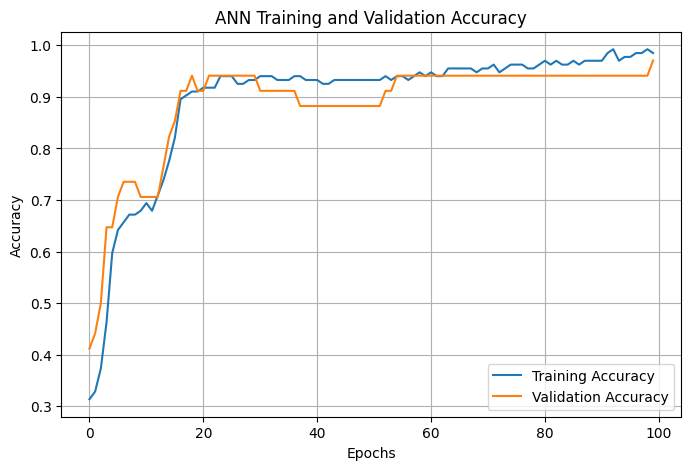

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

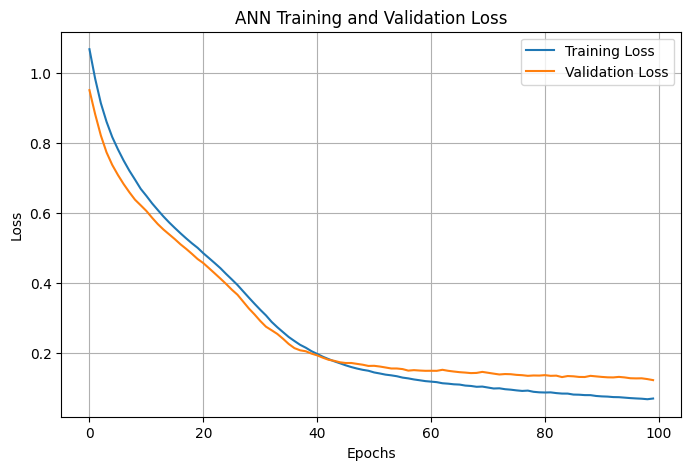

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('ANN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [36]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("Test Loss:",test_loss)
print("Test Accuracy:",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8333 - loss: 0.4500
Test Loss: 0.44999340176582336
Test Accuracy: 0.8333333134651184


In [37]:
y_prob=model.predict(X_test, verbose=1)

print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
[[9.9481767e-01 2.5026532e-04 4.9320459e-03]
 [1.3982760e-02 1.2283892e-06 9.8601598e-01]
 [8.3938295e-01 1.2890236e-01 3.1714622e-02]
 [1.3729389e-04 1.6492957e-09 9.9986273e-01]
 [2.9038091e-03 9.9704951e-01 4.6716152e-05]]


In [38]:
y_pred= np.argmax(y_prob, axis=1)

print(y_pred[:10])

[0 2 0 2 1 2 1 1 1 1]


In [39]:
y_pred_original= y_pred+1
y_test_original= y_test+1

print("Predicted classes:")
print(y_pred_original[:10])

Predicted classes:
[1 3 1 3 2 3 2 2 2 2]


In [40]:
comparison = pd.DataFrame({
    "Actual": y_test_original.values,
    "Predicted": y_pred_original
})

comparison.head(15)

,Actual,Predicted
0,1,1
1,3,3
2,2,1
3,3,3
4,2,2
5,3,3
6,2,2
7,1,2
8,2,2
9,2,2


In [41]:
accuracy= accuracy_score(y_test_original, y_pred_original)
print("Accuracy:", accuracy)

Accuracy: 0.8333333333333334


In [42]:
precision=precision_score(y_test_original, y_pred_original, average="weighted")
print("Precision:", precision)

Precision: 0.8416394335511983


In [43]:
recall= recall_score(y_test_original, y_pred_original, average="weighted")
print("Recall:", recall)

Recall: 0.8333333333333334


In [44]:
f1=f1_score(y_test_original, y_pred_original, average="weighted")
print("F1 Score:", f1)

F1 Score: 0.8218482156771078


In [45]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       0.89      0.57      0.70        14
           2       0.81      0.93      0.87        14
           3       0.82      1.00      0.90        14

    accuracy                           0.83        42
   macro avg       0.84      0.83      0.82        42
weighted avg       0.84      0.83      0.82        42



In [46]:
cm=confusion_matrix(y_test_original, y_pred_original)

print(cm)

[[ 8  3  3]
 [ 1 13  0]
 [ 0  0 14]]


Text(70.72222222222221, 0.5, 'True Labels')

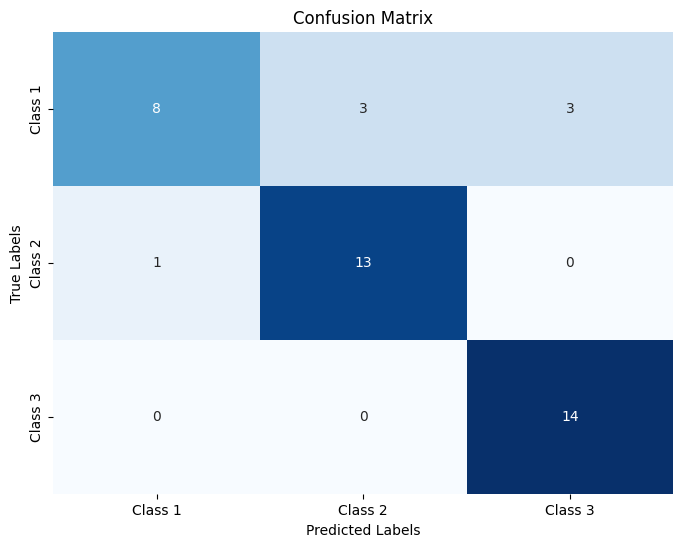

In [47]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Class 1","Class 2", "Class 3"],
    yticklabels=sorted(["Class 1","Class 2", "Class 3"])
    )
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")